## Exercise 12.2 (Classification of multivariate time series)  

- Load the UWaveGestureLibrary data set.
- Use the time series k nearest neighbour algorithm to classify the time series.
- Use the CNN classifier to classify the time series.
- How do the results compare?

# 1 Load the UWaveGestureLibrary data set. 

In [1]:
from sktime.datasets import load_UCR_UEA_dataset

# Datensatz und Format entsprechend dem Hinweis im Skript festlegen.
ds_name = "UWaveGestureLibrary"
ret_type = "numpy3d"

# Trainingsdaten laden. Die Liste erlaubt unterschiedlich lange Zeitreihen.
X_train, y_train = load_UCR_UEA_dataset(
    name=ds_name,
    split="train",
    return_type=ret_type,
)

# Testdaten im gleichen Format laden.
X_test, y_test = load_UCR_UEA_dataset(
    name=ds_name,
    split="test",
    return_type=ret_type,
)

print("Anzahl Trainingszeitreihen:", len(X_train))
print("Anzahl Testzeitreihen:", len(X_test))

Anzahl Trainingszeitreihen: 120
Anzahl Testzeitreihen: 320


# 2 Use the time series k nearest neighbour algorithm to classify the time series.

Genauigkeit auf den Testdaten: 90.31%
Laufzeit für Training und Vorhersage: 23.94 Sekunden.


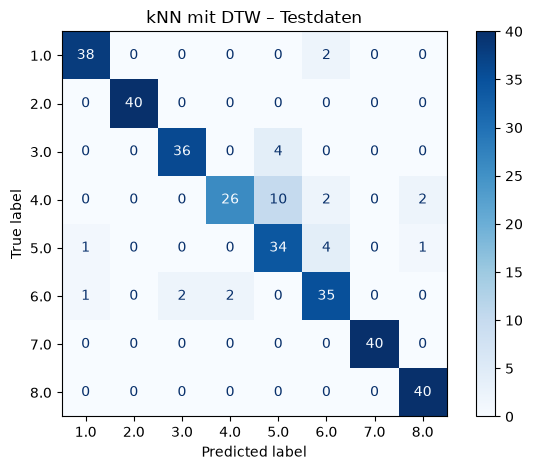

In [2]:
import time
import matplotlib.pyplot as plt
from sktime.classification.distance_based import KNeighborsTimeSeriesClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# 1. Klassifikator mit einem nächsten Nachbarn und DTW-Distanz erstellen.
knn = KNeighborsTimeSeriesClassifier(
    n_neighbors=1,      # nur ein Nachbar
    distance="dtw"      # Distanzmaß: Dynamic Time Warping
)

# 2. Trainingszeitreihen und zugehörige Klassen übergeben.
start_time = time.time()

knn.fit(X_train, y_train)

# 3. Klassen der bisher nicht verwendeten Testzeitreihen vorhersagen.
y_pred_knn = knn.predict(X_test)

duration_knn = time.time() - start_time

# 4. Vorhersagen mit den bekannten Testklassen vergleichen.
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print(f"Genauigkeit auf den Testdaten: {accuracy_knn:.2%}")
print(f"Laufzeit für Training und Vorhersage: {duration_knn:.2f} Sekunden.")

# 5. Richtige und falsche Zuordnungen je Klasse darstellen.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn,
    cmap="Blues"
)

plt.title("kNN mit DTW – Testdaten")
plt.tight_layout()
plt.show()

# 3 Use the CNN classifier to classify the time series.

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 315, 3)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 309, 6)         │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling1d               │ (None, 103, 6)         │             0 │
│ (AveragePooling1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 97, 12)         │           516 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling1d_1             │ (None, 32, 12)         │             0 │
│ (AveragePooling1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │         3,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,728 (14.56 KB)

 Trainable params: 3,728 (14.56 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.0750 - loss: 2.1601  
Epoch 2/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.5583 - loss: 1.7397
Epoch 3/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.7000 - loss: 1.2106
Epoch 4/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.8167 - loss: 0.7248
Epoch 5/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.8667 - loss: 0.4778 
Epoch 6/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.9083 - loss: 0.3336
Epoch 7/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9250 - loss: 0.2343
Epoch 8/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.9667 - loss: 0.1287
Epoch 9/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9833 - loss: 0.0656 
Epoch 10/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9917 - loss: 0.0448
Epoch 11/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 1.0000 - loss: 0.0208
Epoch 12/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 1.0000 - loss: 0.01

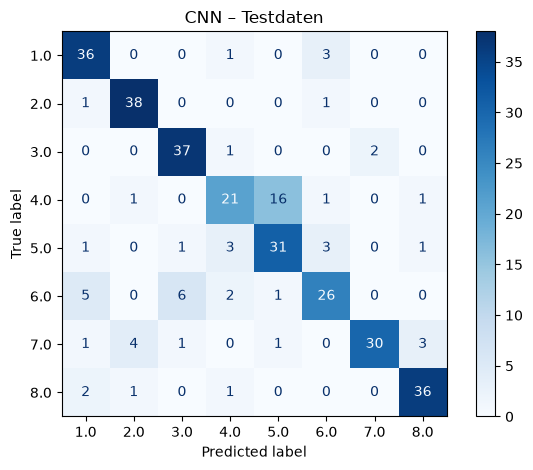

In [3]:
import time
import matplotlib.pyplot as plt
from sktime.classification.deep_learning.cnn import CNNClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# 1. CNN für die Klassifikation erstellen.
# Softmax liefert die Klassenwahrscheinlichkeiten.
cnn = CNNClassifier(
    n_epochs=80,
    batch_size=64,
    n_conv_layers=2,
    activation="softmax",
    activation_hidden="relu",
    random_state=42,
    verbose=True
)

# 2. CNN ausschließlich mit den Trainingsdaten trainieren.
start_time = time.time()

cnn.fit(X_train, y_train)

# 3. Klassen der Testzeitreihen vorhersagen.
y_pred_cnn = cnn.predict(X_test)

duration_cnn = time.time() - start_time

# 4. Vorhersagen anhand der bekannten Testklassen bewerten.
accuracy_cnn = accuracy_score(y_test, y_pred_cnn)

print(f"Genauigkeit auf den Testdaten: {accuracy_cnn:.2%}")
print(f"Laufzeit für Training und Vorhersage: {duration_cnn:.2f} Sekunden.")

# 5. Richtige Zuordnungen und Verwechslungen darstellen.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_cnn,
    cmap="Blues"
)

plt.title("CNN – Testdaten")
plt.tight_layout()
plt.show()

# 4 How do the results compare?

kNN mit DTW erkennt 289 von 320 Testgesten korrekt und erreicht eine Genauigkeit von 90,31 %. Das CNN erkennt 255 Gesten korrekt und erreicht 79,69 %. Damit liefert kNN im vorliegenden Versuch das bessere Ergebnis.

Beide Verfahren verwechseln besonders häufig Klasse 4 mit Klasse 5. Beim CNN treten zusätzlich mehr Fehler auf, insbesondere bei den Klassen 6 und 7.

DTW berücksichtigt unterschiedliche zeitliche Abläufe ähnlicher Gesten ausdrücklich. Das CNN muss passende Merkmale aus den Trainingsdaten lernen. Seine Trainingsparameter wurden nicht für diesen Datensatz optimiert. Durch angepasste Parameter oder eine geeignete Skalierung könnte noch Verbesserungspotenzial bestehen. Ob dadurch bessere Ergebnisse erzielt würden, müsste anhand separater Validierungsdaten geprüft werden.

ipynb exportiert als html mit:

uv run jupyter nbconvert --to html "Tasks/12 Self study - Session 3/Exercise_12.2.ipynb"